In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import seaborn as sns
from analysis.utils import get_per_position_data, first_steps_to_threshold

sns.set_style(style="darkgrid")

In [2]:
data = get_per_position_data(tag="karity-1", subset="embed_cond")

Found 3 runs with tag 'karity-1'


In [3]:
def plot_steps(data, K, threshold, subset="embed_cond"):
    k_data = data[data["cfg.dataset_metadata.K"] == K]
    assert len(k_data) > 0, f"No data for K={K}"

    steps = first_steps_to_threshold(k_data, subset, threshold)

    plt.figure(figsize=(16, 6))
    plt.plot(steps.index, steps.values, marker="o")

    plt.xlabel("Suffix Position", fontsize=16)
    plt.ylabel(f"First Step to Acc ≥ {threshold}", fontsize=16)
    plt.title(f"K={K}", fontsize=18)
    plt.xticks(steps.index, fontsize=14)
    plt.yticks(fontsize=14)

    plt.tight_layout()
    plt.show()

def plot_all_ks(data, threshold, subset="embed_cond"):
    plt.figure(figsize=(16, 6))
    for K in sorted(data["cfg.dataset_metadata.K"].unique()):
        k_data = data[data["cfg.dataset_metadata.K"] == K]
        steps = first_steps_to_threshold(k_data, subset, threshold)
        plt.plot(steps.index, steps.values, marker="o", label=f"K={K}")
    plt.xlabel("Suffix Position", fontsize=16)
    plt.ylabel(f"First Step to Acc ≥ {threshold}", fontsize=16)
    plt.legend(fontsize=14)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.tight_layout()
    plt.show()

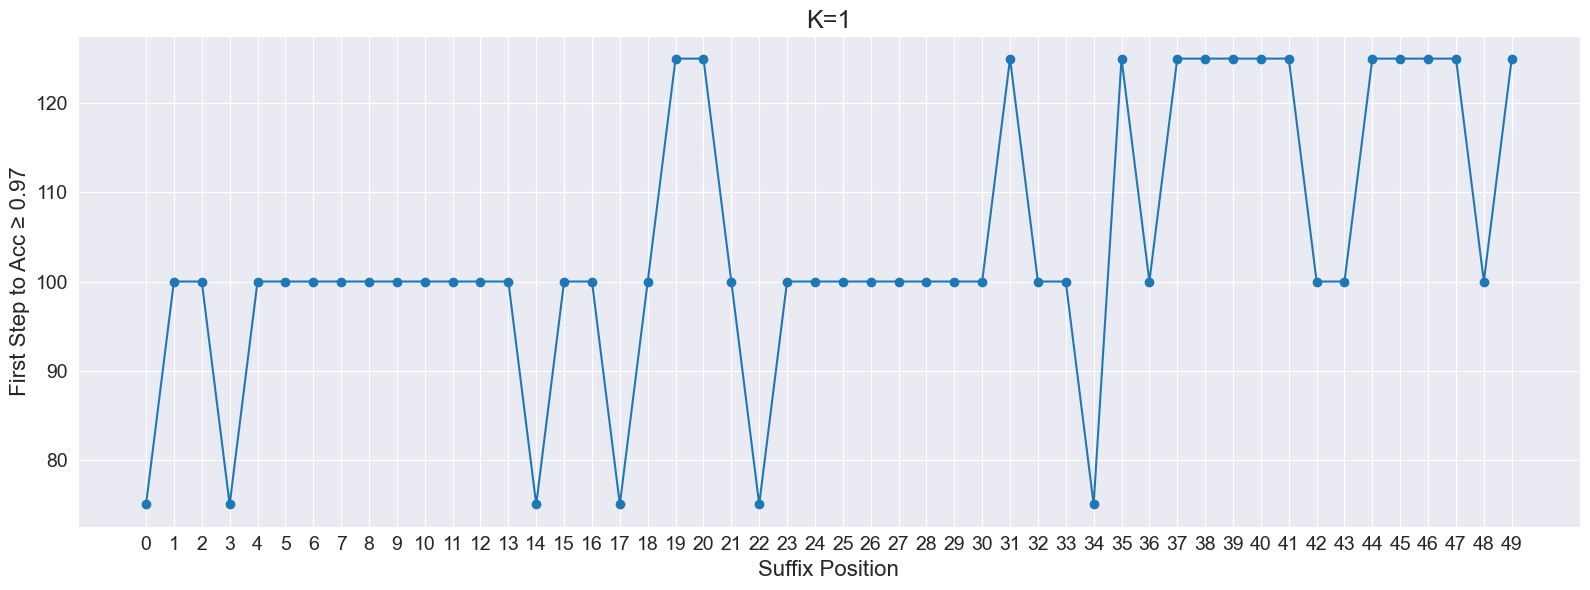

In [4]:
plot_steps(data, K=1, threshold=0.97)

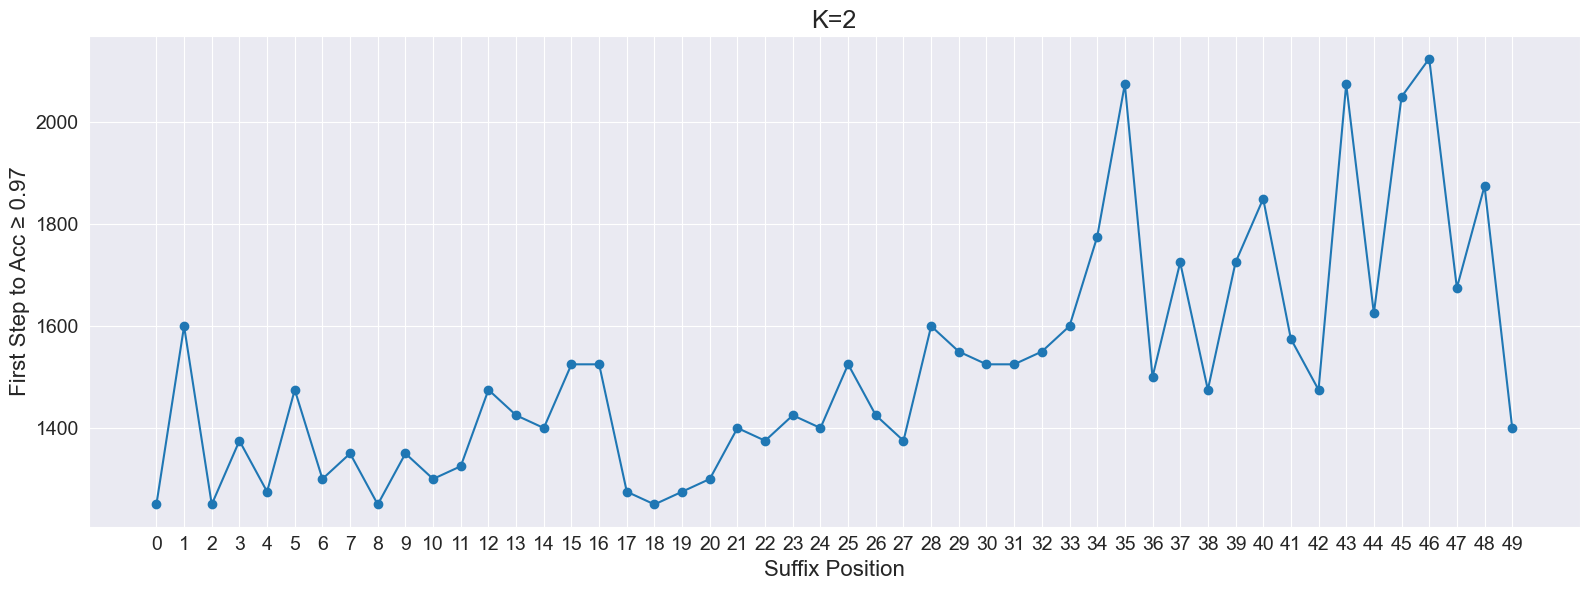

In [5]:
plot_steps(data, K=2, threshold=0.97)

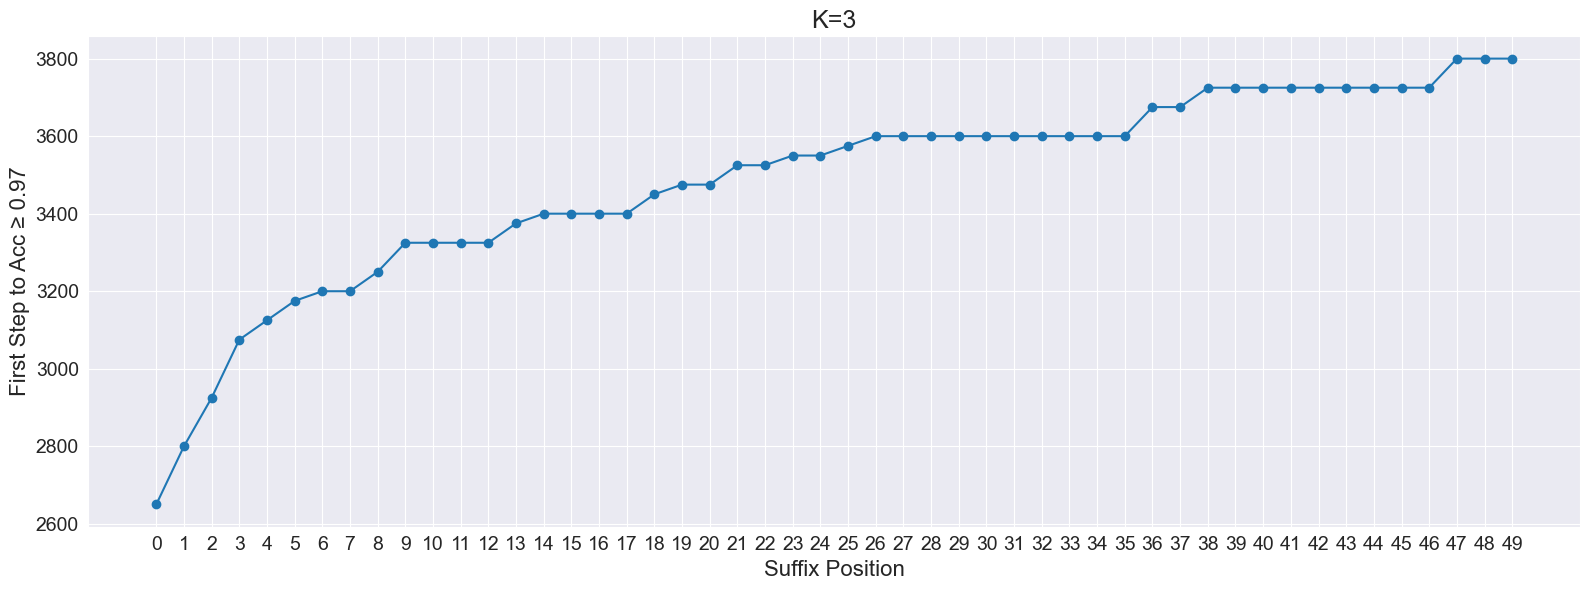

In [6]:
plot_steps(data, K=3, threshold=0.97)

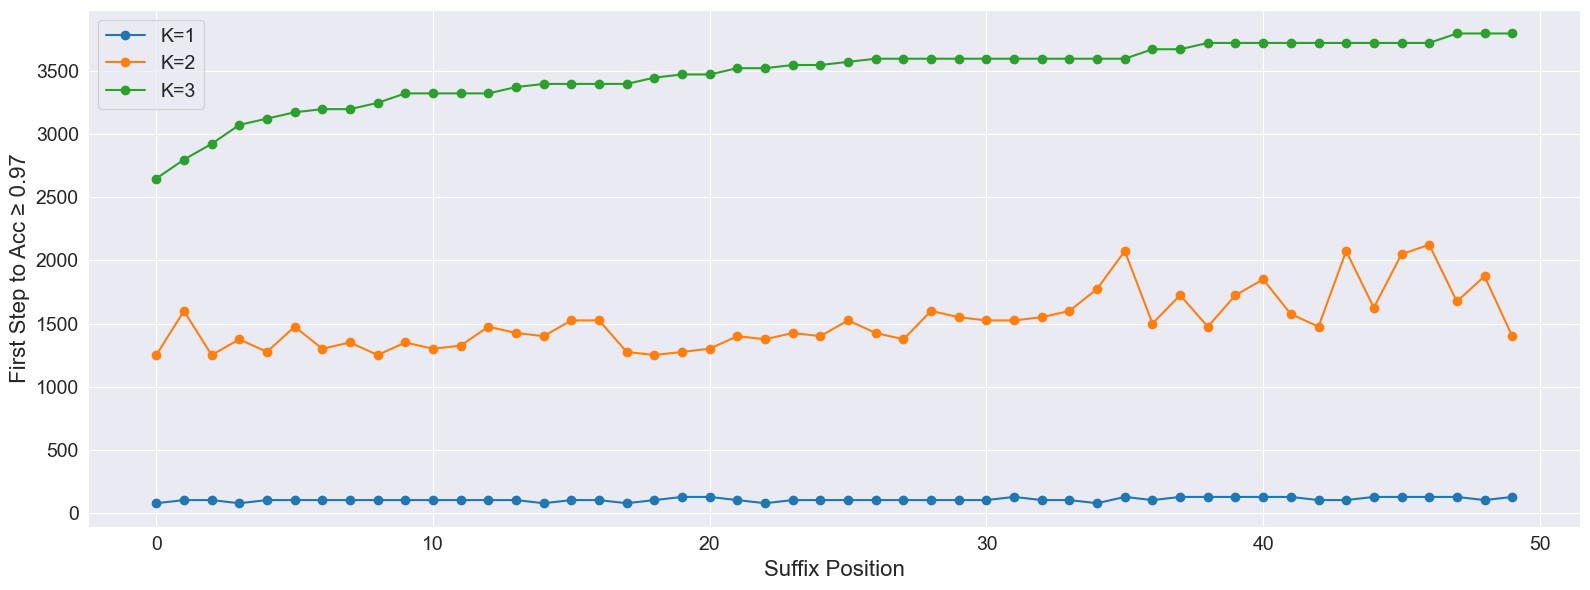

In [7]:
plot_all_ks(data, threshold=0.97)